In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [4]:
print(X.describe())
print(X.corrwith(y).sort_values())

             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude  
count  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704  
std       10.386050      2.135952      2.003532  
min        0.692308     32.540000   -124.350000  
25%        2.429741     33.930000   -1

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [7]:
from sklearn.metrics import mean_squared_error, r2_score

baseline_pred = np.full_like(y_test, y_train.mean())
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
print(baseline_rmse)   # about 1.15

1.1448563543099792


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)
pred = model.predict(X_test)

In [9]:
rmse = np.sqrt(mean_squared_error(y_test, pred))
print(f"Baseline RMSE: {baseline_rmse:.3f}")
print(f"Model RMSE:    {rmse:.3f}")
print(f"R²:            {r2_score(y_test, pred):.3f}")

Baseline RMSE: 1.145
Model RMSE:    0.746
R²:            0.576


In [10]:
coefs = pd.Series(model[-1].coef_, index=X.columns).sort_values()
print(coefs)

Latitude     -0.896929
Longitude    -0.869842
AveRooms     -0.294410
AveOccup     -0.040829
Population   -0.002308
HouseAge      0.122546
AveBedrms     0.339259
MedInc        0.854383
dtype: float64


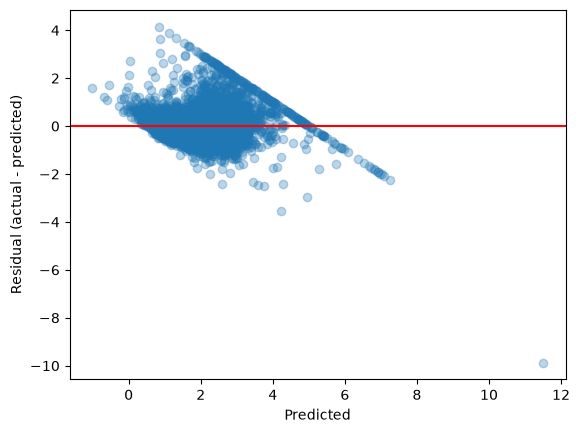

In [11]:
residuals = y_test - pred
plt.scatter(pred, residuals, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Predicted"); plt.ylabel("Residual (actual - predicted)")
plt.show()